# 03 · BH está entre os municípios com maior IPS da RMBH?

> Parte 3 de 6 do projeto *BH e Região sob a perspectiva dos dados*. Veja o [README](../README.md) para a visão geral.

In [1]:
# Configuração: funciona no computador (a partir da pasta notebooks/) e no Google Colab
import os
import subprocess
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo = Path('/content/ips-bh-rmbh')
    if not repo.exists():
        subprocess.run(['git', 'clone', '-q', 'https://github.com/millebns/ips-bh-rmbh.git', str(repo)], check=True)
    os.chdir(repo / 'notebooks')

sys.path.insert(0, str(Path.cwd().parent / 'src'))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from functools import partial

from ips_rmbh import analise
from ips_rmbh.config import BH, COR_BH, COR_OUTROS, COR_DESTAQUE, PASTA_FIGURAS
from ips_rmbh.dados import carregar_rmbh

df_rmbh = carregar_rmbh()

# Atalhos que comparam BH com os demais municípios da RMBH
posicao_bh = partial(analise.posicao, df_rmbh)
valor_bh = partial(analise.valor, df_rmbh)
print(df_rmbh.shape)

(34, 78)


## Perguntas de negócio do projeto

1. Belo Horizonte está entre os municípios com maior IPS da Região Metropolitana?
2. Como Belo Horizonte se compara aos municípios da sua Região Metropolitana em qualidade de vida, segurança e desenvolvimento econômico?
3. Como Belo Horizonte se posiciona especificamente em segurança?

Na pergunta 2, qualidade de vida e segurança são avaliadas pelos componentes do IPS. **O IPS não inclui variáveis econômicas**: ele mede resultados sociais. Por isso, o desenvolvimento econômico é avaliado pela coluna `PIB PER CAPITA`, que a base traz como informação complementar.

**Leitura dos indicadores:** as notas do IPS, das dimensões e dos componentes vão de 0 a 100, e maior é melhor. Nos indicadores brutos de taxas (homicídios, mortes no trânsito etc.), menor é melhor.

# Pergunta 1: ranking do IPS na RMBH

In [3]:
ips_rank = (df_rmbh[['Município', 'Índice de Progresso Social']]
            .sort_values('Índice de Progresso Social', ascending=False)
            .reset_index(drop=True))
ips_rank['rank'] = ips_rank['Índice de Progresso Social'].rank(ascending=False, method='min').astype(int)

mediana_ips = df_rmbh['Índice de Progresso Social'].median()
print(f'BH: {posicao_bh("Índice de Progresso Social")}º de 34 | mediana da RMBH: {mediana_ips:.2f}')

BH: 3º de 34 | mediana da RMBH: 63.69


In [4]:
ips_rank.head(5)

,Município,Índice de Progresso Social,rank
0,Nova Lima,71.22,1
1,Confins,69.67,2
2,Belo Horizonte,69.66,3
3,Sarzedo,68.47,4
4,Contagem,67.57,5


In [5]:
ips_rank.tail(5)

,Município,Índice de Progresso Social,rank
29,Rio Manso,60.50,30
30,Capim Branco,60.23,31
31,Jaboticatubas,58.79,32
32,Taquaraçu de Minas,57.75,33
33,Baldim,57.01,34


In [6]:
ordenado = ips_rank.sort_values('Índice de Progresso Social')
cores = [COR_BH if m == BH else COR_OUTROS for m in ordenado['Município']]
inicio = ordenado['Índice de Progresso Social'].min() - 1


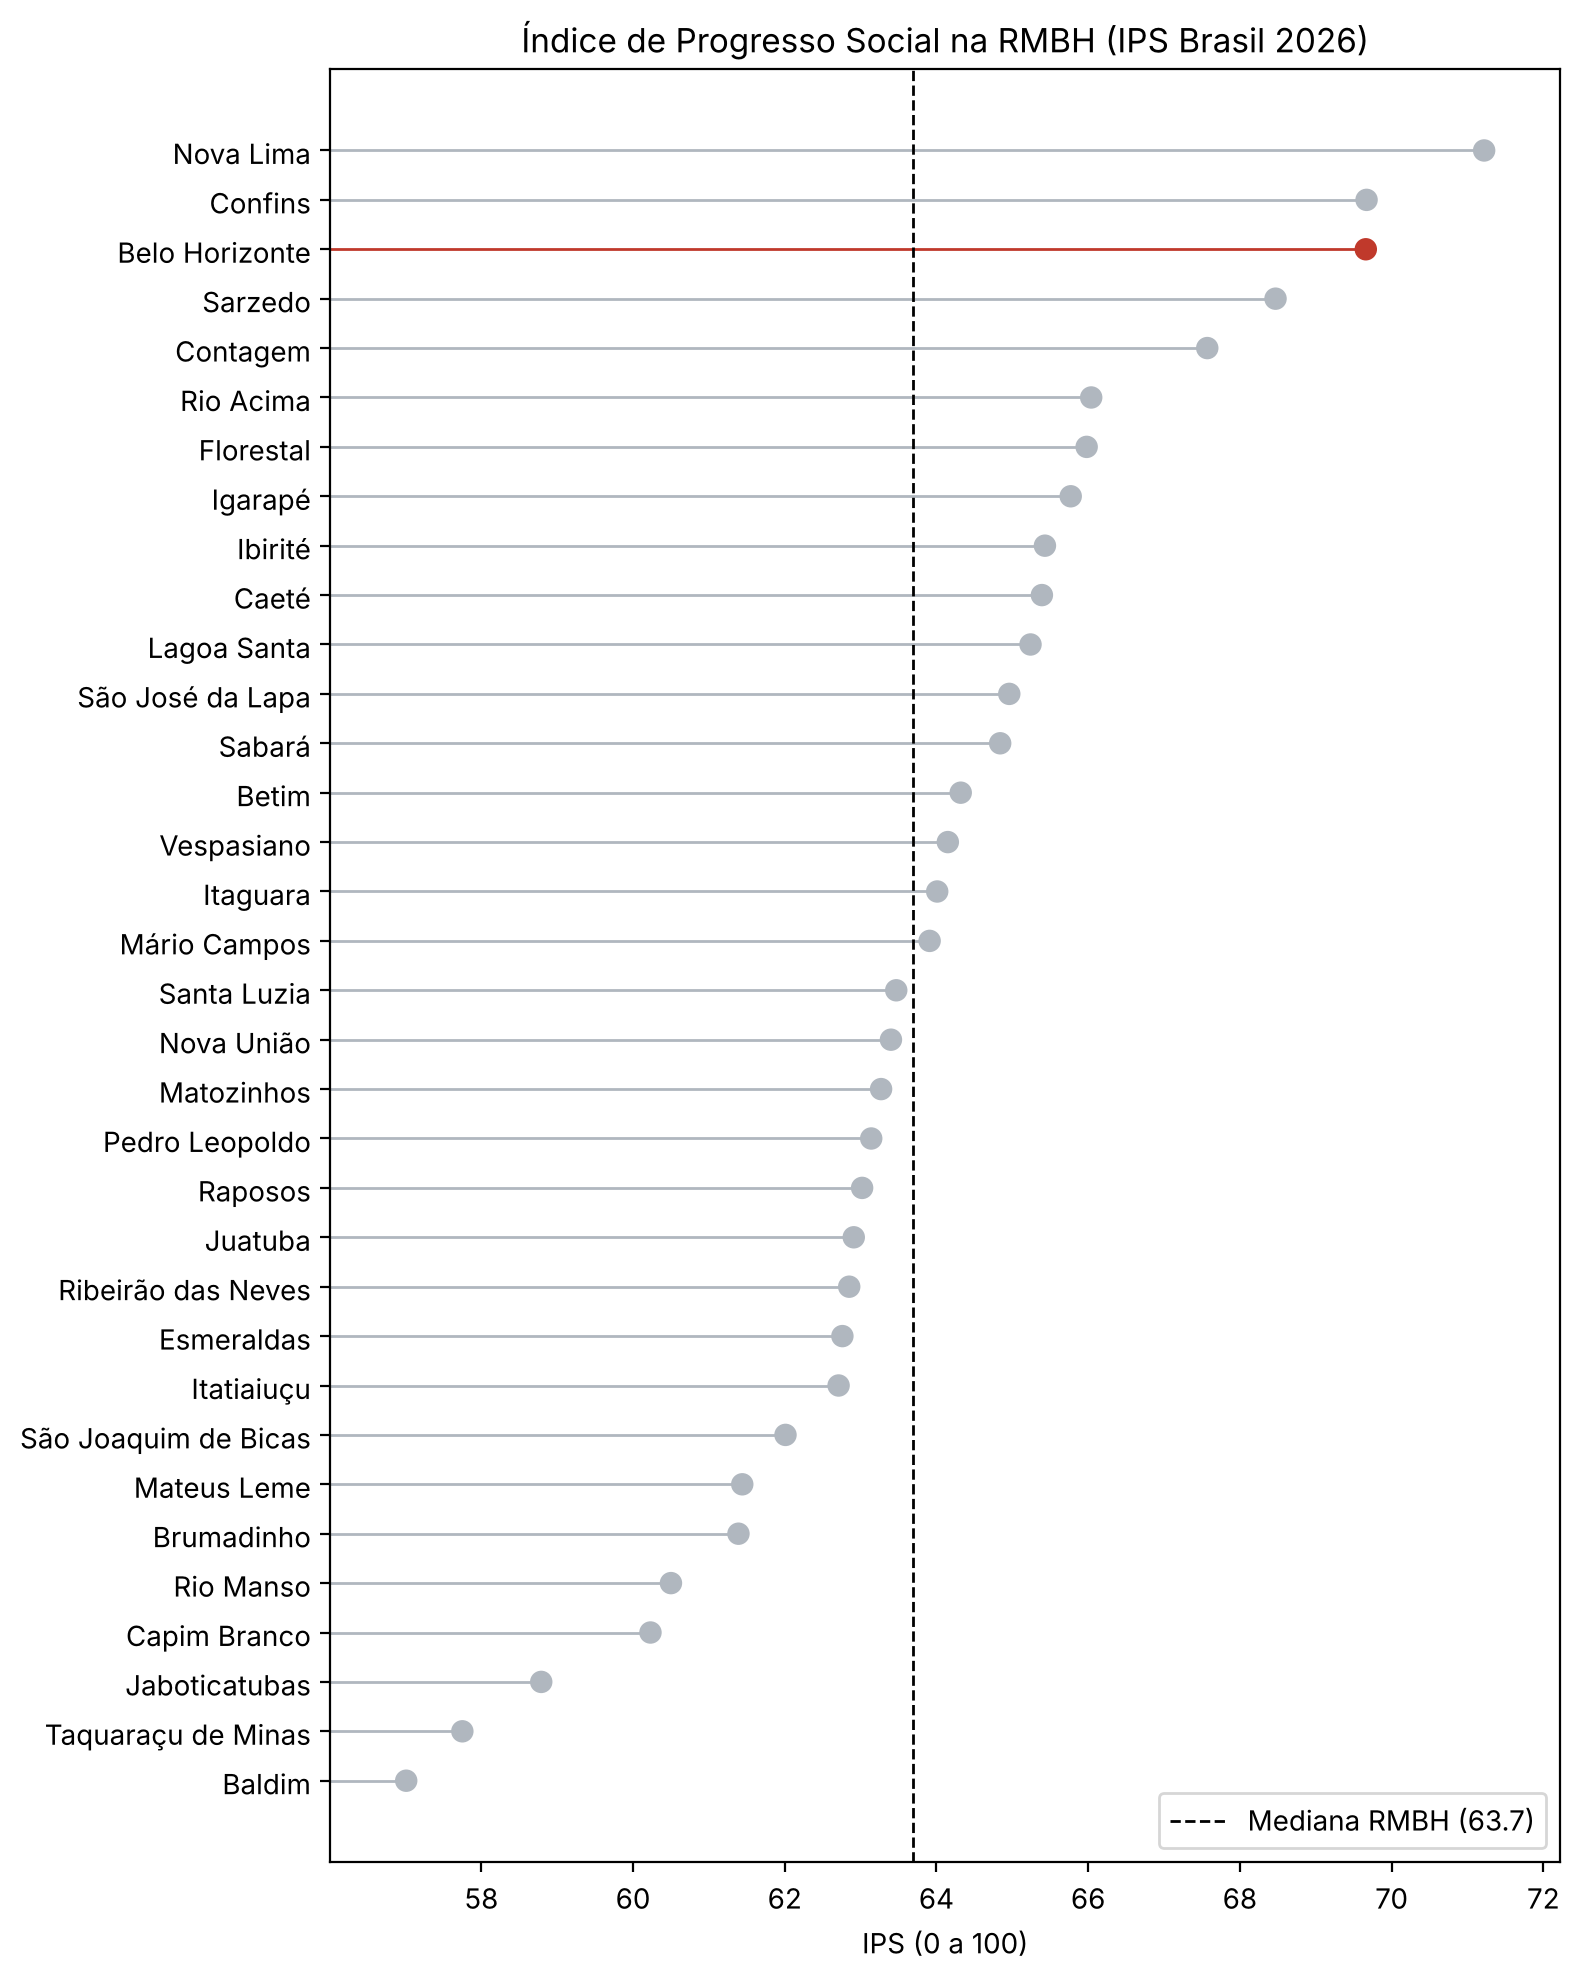

In [7]:
fig, ax = plt.subplots(figsize=(8, 10))
ax.hlines(ordenado['Município'], inicio, ordenado['Índice de Progresso Social'], color=cores, lw=1)
ax.scatter(ordenado['Índice de Progresso Social'], ordenado['Município'], color=cores, s=50, zorder=3)
ax.axvline(mediana_ips, ls='--', c='black', lw=1, label=f'Mediana RMBH ({mediana_ips:.1f})')
ax.set_xlim(inicio, ordenado['Índice de Progresso Social'].max() + 1)
ax.set_title('Índice de Progresso Social na RMBH (IPS Brasil 2026)')
ax.set_xlabel('IPS (0 a 100)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / '01_ips_rmbh.png', dpi=150, bbox_inches='tight')
plt.show()

**Resposta:** sim. BH tem o **3º maior IPS da RMBH (69,66)**, atrás de Nova Lima (71,22) e praticamente empatada com Confins (69,67), uma diferença de 0,01 ponto. A mediana da região é 63,69. Vale notar que Confins tem cerca de 7,8 mil habitantes, contra 2,4 milhões de BH.


**Próximo notebook:** [04 · Dimensões, componentes e inclusão social](04_componentes_e_inclusao.ipynb)